In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("consumer_complaints_output.csv")
df

,date_received,PRODUCT,issue,company,state,zipcode,submitted_via,date_sent_to_company,company_response_to_consumer,timely_response,consumer_disputed?,complaint_id
0,08/18/2015,MORTGAGE,"Loan servicing, payments, escrow account",PHH Mortgage,AA,340XX,Web,08/18/2015,Closed with explanation,Yes,Yes,1524422
1,11/03/2013,STUDENT LOAN,Problems when you are unable to pay,KeyBank NA,AA,73160,Web,11/08/2013,Closed with explanation,Yes,No,582697
2,02/20/2013,MORTGAGE,"Loan modification,collection,foreclosure",Wells Fargo & Company,AA,98282,Referral,02/22/2013,Closed with explanation,Yes,No,322779
3,04/14/2016,CREDIT CARD,Rewards,Discover,AA,857XX,Web,04/14/2016,Closed with explanation,Yes,Yes,1880793
4,01/07/2014,BANK ACCOUNT OR SERVICE,"Account opening, closing, or management",Capital One,AA,34030,Web,01/14/2014,Closed with explanation,Yes,No,657556
...,...,...,...,...,...,...,...,...,...,...,...,...
555952,04/23/2014,DEBT COLLECTION,Cont'd attempts collect debt not owed,Discover,WY,82935,Web,04/25/2014,Closed with explanation,Yes,No,821399
555953,06/02/2014,CREDIT REPORTING,Incorrect information on credit report,"TransUnion Intermediate Holdings, Inc.",WY,82001,Web,06/05/2014,Closed with explanation,Yes,No,876311
555954,01/05/2016,CREDIT CARD,Other,Wells Fargo & Company,WY,82501,Web,01/05/2016,Closed with explanation,Yes,No,1728054
555955,01/09/2013,MORTGAGE,"Loan modification,collection,foreclosure",Bank of America,WY,83118,Referral,01/11/2013,Closed with non-monetary relief,Yes,No,225266


In [3]:
df.columns

Index(['date_received', 'PRODUCT', 'issue', 'company', 'state', 'zipcode',
       'submitted_via', 'date_sent_to_company', 'company_response_to_consumer',
       'timely_response', 'consumer_disputed?', 'complaint_id'],
      dtype='str')

In [4]:
state_complaints = df.groupby("state")["complaint_id"].count().sort_values(ascending=True).head()
state_complaints


state
AA     9
PW     9
AS    17
MP    19
MH    27
Name: complaint_id, dtype: int64

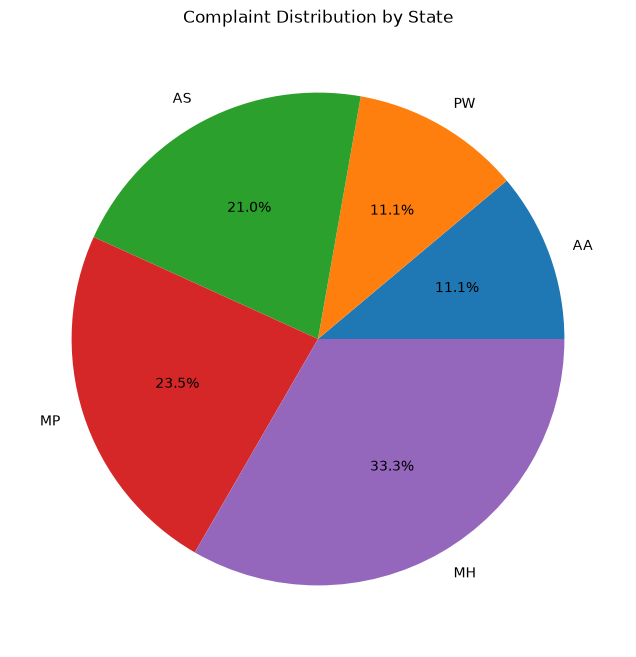

In [5]:
#piechart
#percentage distribution of complaints across states.
state_complaints.plot(
    kind="pie",
    figsize=(8, 8),
    autopct="%1.1f%%",
    title="Complaint Distribution by State"
)

plt.ylabel("")
plt.show()

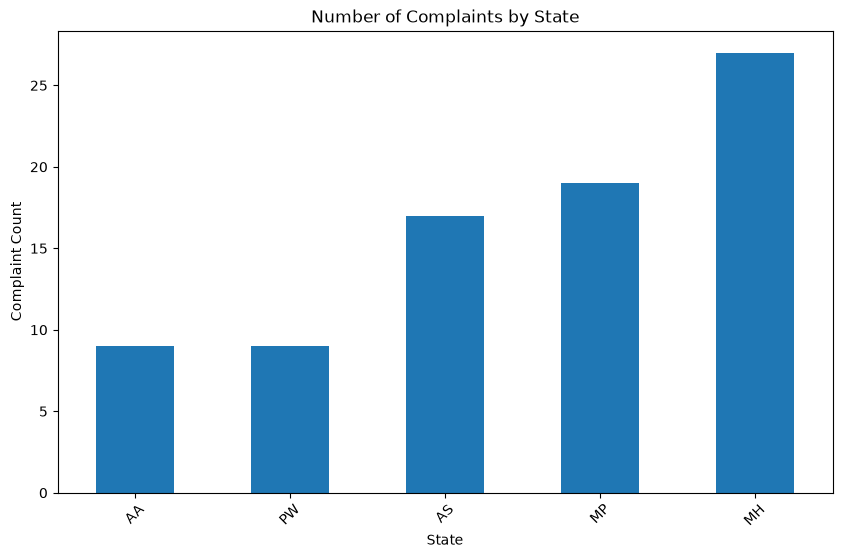

In [6]:
#bar chart showing the number of complaints in each state.
state_complaints.plot(
    kind="bar",
    figsize=(10, 6),
    title="Number of Complaints by State"
)

plt.xlabel("State")
plt.ylabel("Complaint Count")
plt.xticks(rotation=45)
plt.show()

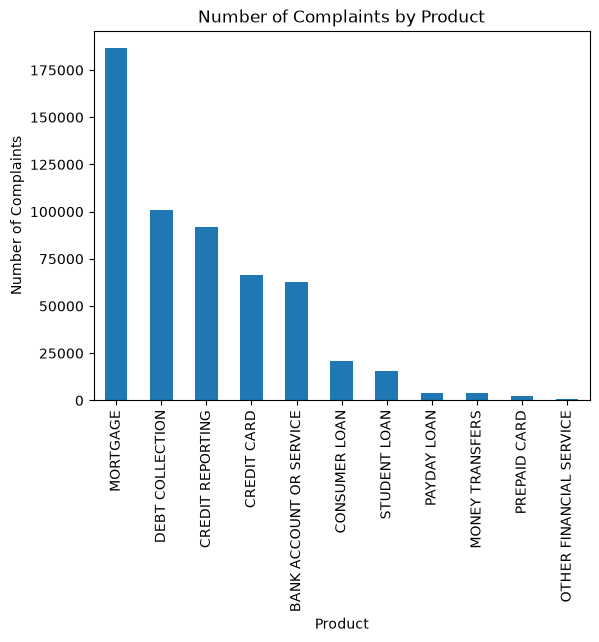

In [7]:
#bar chart showing the number of complaints for each product.
import matplotlib.pyplot as plt

product_count = df["PRODUCT"].value_counts()

product_count.plot(kind="bar")

plt.title("Number of Complaints by Product")
plt.xlabel("Product")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=90)

plt.show()

In [8]:
df

,date_received,PRODUCT,issue,company,state,zipcode,submitted_via,date_sent_to_company,company_response_to_consumer,timely_response,consumer_disputed?,complaint_id
0,08/18/2015,MORTGAGE,"Loan servicing, payments, escrow account",PHH Mortgage,AA,340XX,Web,08/18/2015,Closed with explanation,Yes,Yes,1524422
1,11/03/2013,STUDENT LOAN,Problems when you are unable to pay,KeyBank NA,AA,73160,Web,11/08/2013,Closed with explanation,Yes,No,582697
2,02/20/2013,MORTGAGE,"Loan modification,collection,foreclosure",Wells Fargo & Company,AA,98282,Referral,02/22/2013,Closed with explanation,Yes,No,322779
3,04/14/2016,CREDIT CARD,Rewards,Discover,AA,857XX,Web,04/14/2016,Closed with explanation,Yes,Yes,1880793
4,01/07/2014,BANK ACCOUNT OR SERVICE,"Account opening, closing, or management",Capital One,AA,34030,Web,01/14/2014,Closed with explanation,Yes,No,657556
...,...,...,...,...,...,...,...,...,...,...,...,...
555952,04/23/2014,DEBT COLLECTION,Cont'd attempts collect debt not owed,Discover,WY,82935,Web,04/25/2014,Closed with explanation,Yes,No,821399
555953,06/02/2014,CREDIT REPORTING,Incorrect information on credit report,"TransUnion Intermediate Holdings, Inc.",WY,82001,Web,06/05/2014,Closed with explanation,Yes,No,876311
555954,01/05/2016,CREDIT CARD,Other,Wells Fargo & Company,WY,82501,Web,01/05/2016,Closed with explanation,Yes,No,1728054
555955,01/09/2013,MORTGAGE,"Loan modification,collection,foreclosure",Bank of America,WY,83118,Referral,01/11/2013,Closed with non-monetary relief,Yes,No,225266


In [9]:
#how many complaints belong to the Mortgage product category.
mortgage_count = (df["PRODUCT"] == "MORTGAGE").sum()

print("Number of Mortgage Complaints:", mortgage_count)

Number of Mortgage Complaints: 186475


In [10]:
#how many complaints belong to the debt collection product category.
debt_count = (df["PRODUCT"] == "DEBT COLLECTION").sum()

print("Number of Debt Collection Complaints:", debt_count)

Number of Debt Collection Complaints: 101052


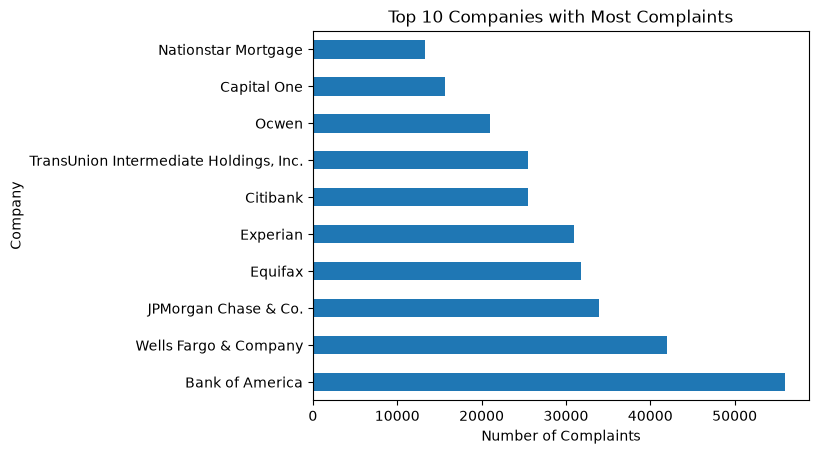

In [21]:
#Horizontal bar chart — top 10 companies
company_count = df["company"].value_counts().head(10)

company_count.plot(kind="barh")

plt.title("Top 10 Companies with Most Complaints")
plt.xlabel("Number of Complaints")
plt.ylabel("Company")

plt.show()

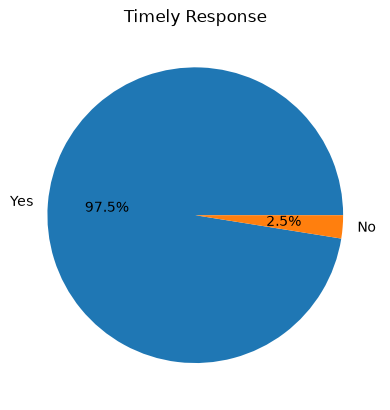

In [12]:
timely_count = df["timely_response"].value_counts()

timely_count.plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Timely Response")
plt.ylabel("")

plt.show()

In [14]:
#check how many Yes and No values are in the timely_response column
yes_count = (df["timely_response"] == "Yes").sum()
no_count = (df["timely_response"] == "No").sum()

print("Yes:", yes_count)
print("No:", no_count)

Yes: 541909
No: 14048


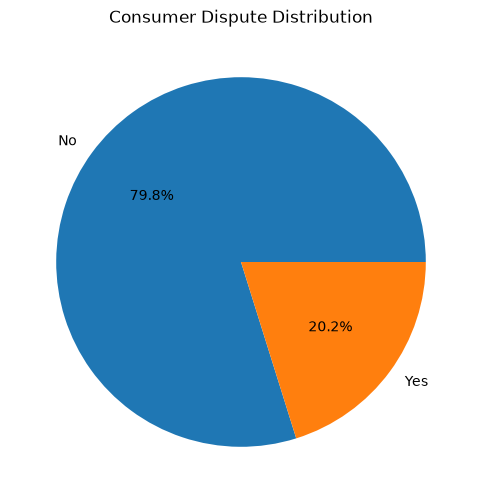

In [15]:
dispute_count = df["consumer_disputed?"].value_counts()

dispute_count.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(6, 6)
)

plt.title("Consumer Dispute Distribution")
plt.ylabel("")
plt.show()

In [19]:
#how many yes and no in consumer_disputed?
yes_count = (df["consumer_disputed?"] == "Yes").sum()
no_count = (df["consumer_disputed?"] == "No").sum()
print("Yes:", yes_count)
print("No:", no_count)

Yes: 112134
No: 443823


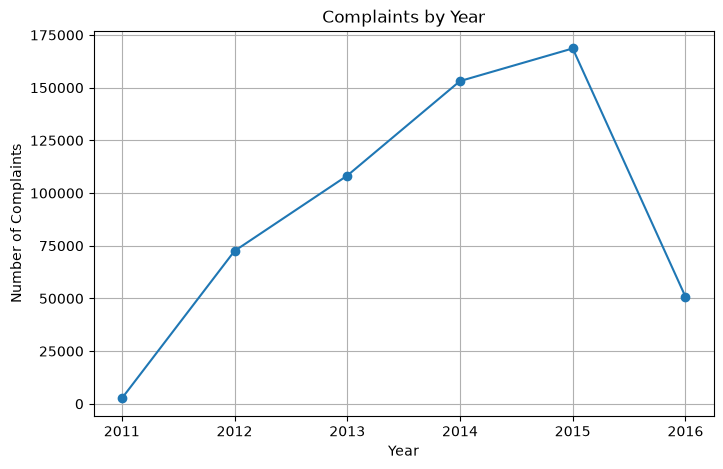

In [20]:
df["date_received"] = pd.to_datetime(df["date_received"]) #Converts the date_received column from text/string into a date format.

df["year"] = df["date_received"].dt.year #Takes only the year from date_received and creates a new column called year

year_count = df["year"].value_counts().sort_index()

year_count.plot(kind="line", marker="o", figsize=(8, 5))

plt.title("Complaints by Year")
plt.xlabel("Year")
plt.ylabel("Number of Complaints")
plt.grid()
plt.show()